# Anexo de inteligencia artificial del carro RC

Grupo 11 · Modelos y Simulación · UNEMI

## 1. Propósito y alcance

La IA es una ampliación fuera de línea: el árbol no corre en el ESP32 ni decide la alarma. El firmware decide la alarma local con sus reglas, independientemente del Wi-Fi. La IA no tiene clase inclinación: el informe emplea una regla independiente a 60°, distinta de los 10° del firmware. El firmware utiliza golpe de 16 m/s² en dos lecturas y vuelco de 90° sostenido 150 ms.

In [1]:
#@title Preparar datos: regenerar desde la base local o leer la instantánea
from pathlib import Path
import sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from matplotlib.ticker import FuncFormatter
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'package.json').exists() and (p/'firmware').is_dir()), None)
if raiz is None:
    raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'anexos/datos/pruebas_fisicas.csv').exists()), Path.cwd())
datos = raiz/'anexos/datos'; figuras = raiz/'anexos/figuras'
datos.mkdir(parents=True, exist_ok=True); figuras.mkdir(parents=True, exist_ok=True)
base = raiz/'servidor/data/accidentes.sqlite'
if base.exists():
    x = pd.read_excel(raiz/'evidencias/fisico/resultados/resultados-simulacion-vs-prototipo.xlsx', sheet_name='Repeticiones')
    pruebas = x[['Escenario esperado','Repetición','Sesión','Clase esperada','Clase detectada']].copy()
    pruebas.columns = ['escenario','rep','run_id','esperado','firmware']
    for col in ['esperado','firmware']: pruebas[col] = pruebas[col].str.lower()
    with sqlite3.connect(f'file:{base}?mode=ro', uri=True) as con:
        limites = pd.read_sql_query('SELECT sesion_id, t_inicio_ms AS limite_inicio, t_fin_ms AS limite_fin FROM pruebas', con)
        partes = {}; 
        for tabla in ['mediciones','eventos']:
            df = pd.read_sql_query(f'SELECT * FROM {tabla}', con)
            df = df.merge(limites, on='sesion_id').merge(pruebas[['run_id']], left_on='sesion_id', right_on='run_id')
            tiempo = 't_ms' if tabla == 'mediciones' else 't_deteccion_ms'
            df = df[(df.limite_inicio.isna() | (df[tiempo]>=df.limite_inicio)) & (df.limite_fin.isna() | (df[tiempo]<=df.limite_fin))]
            partes[tabla] = df.drop(columns=['limite_inicio','limite_fin'])
    muestras, eventos = partes['mediciones'], partes['eventos']
    for df,nombre in [(pruebas,'pruebas_fisicas'),(muestras,'mediciones_pruebas'),(eventos,'eventos_pruebas')]: df.to_csv(datos/(nombre+'.csv'),index=False)
else:
    pruebas, muestras, eventos = [pd.read_csv(datos/(nombre+'.csv')) for nombre in ['pruebas_fisicas','mediciones_pruebas','eventos_pruebas']]
muestras['origin']='real'
print('Pruebas:',len(pruebas),'mediciones:',len(muestras),'eventos:',len(eventos))
plt.rcParams.update({'font.family':'DejaVu Sans','figure.facecolor':'white','axes.facecolor':'white','font.size':8})
plt.rcParams['axes.formatter.use_locale']=False
fmt=FuncFormatter(lambda x,pos: f'{x:g}'.replace('.',','))
def guardar_fig(n,nombre):
    for ax in plt.gcf().axes:
        ax.xaxis.set_major_formatter(fmt) if not ax.get_xticklabels() or all(not t.get_text() for t in ax.get_xticklabels()) else None
    plt.savefig(figuras/f'figura{n}_{nombre}.png',dpi=300,bbox_inches='tight',facecolor='white'); plt.show()
def tabla(df,n,nombre):
    df = df.copy()
    df = df.replace({True: 'sí', False: 'no'}).round(4)
    df.to_csv(datos/f'tabla{n}_{nombre}.csv',index=False, float_format='%.4f')
    display(df.style.format(precision=3,decimal=',',na_rep='—'))


Pruebas: 18 mediciones: 58229 eventos: 17


## 2. Datos utilizados

**Tabla 20**

*Fuentes de datos*

In [2]:
tabla(pd.DataFrame([['Repeticiones físicas',len(pruebas),'Excel y pruebas de SQLite'],['Mediciones en las ventanas',len(muestras),'SQLite'],['Eventos en las ventanas',len(eventos),'SQLite'],['Calibración real',13,'APP de nivel del celular'],['Corridas sintéticas',78,'Generador arbol-rc-0.2']],columns=['Datos','Cantidad','Origen']),20,'fuentes')

,Datos,Cantidad,Origen
0,Repeticiones físicas,18,Excel y pruebas de SQLite
1,Mediciones en las ventanas,58229,SQLite
2,Eventos en las ventanas,17,SQLite
3,Calibración real,13,APP de nivel del celular
4,Corridas sintéticas,78,Generador arbol-rc-0.2


*Nota.* Las mediciones y eventos se limitan a los intervalos registrados de cada sesión. Fuente: archivos del proyecto y generador sintético. Elaboración propia.

## 3. Modelo

Se reproduce el generador sintético y el árbol arbol-rc-0.2 con semilla 42. Se extraen ventanas de 0,5 s cada 0,1 s y se separan corridas completas por escenario; no se mezclan ventanas de una corrida entre entrenamiento y prueba. El árbol usa profundidad máxima 4, mínimo de 5 muestras por hoja y pesos equilibrados por clase.

**Tabla 21**

*Características de cada ventana*

In [3]:
tabla(pd.DataFrame([['acc_dyn_peak','Desviación máxima de la gravedad','m/s²'],['acc_norm_delta_peak','Cambio máximo de la norma entre muestras','m/s²'],['longitudinal_min_smooth','Mínimo longitudinal suavizado','m/s²'],['tilt_peak_deg','Inclinación máxima','°'],['tilt_time_s','Tiempo por encima de 90°','s']],columns=['Variable','Lectura física','Unidad']),21,'caracteristicas')

,Variable,Lectura física,Unidad
0,acc_dyn_peak,Desviación máxima de la gravedad,m/s²
1,acc_norm_delta_peak,Cambio máximo de la norma entre muestras,m/s²
2,longitudinal_min_smooth,Mínimo longitudinal suavizado,m/s²
3,tilt_peak_deg,Inclinación máxima,°
4,tilt_time_s,Tiempo por encima de 90°,s


*Nota.* El suavizado longitudinal usa 0,1 s. Fuente: cuaderno original de la IA. Elaboración propia.

In [4]:
#@title Generar las corridas sintéticas de la versión 0.2
SEED = 42
np.random.seed(SEED)
G = 9.81
MODEL_VERSION = "arbol-rc-0.2"
CLASSES = ["normal", "frenada", "impacto", "vuelco"]
FEATURES = ["acc_dyn_peak", "acc_norm_delta_peak", "longitudinal_min_smooth",
            "tilt_peak_deg", "tilt_time_s"]
REQUIRED = ["run_id", "origin", "t_ms", "ax", "ay", "az", "roll_deg", "pitch_deg"]

# Umbrales del informe: provisionales, se recalibran con corridas físicas.
BRAKE_THRESHOLD = -4.0      # m/s², mínimo de ax suavizado (0,1 s) para llamar "frenada brusca"
ROLLOVER_DEG = 90.0         # inclinación a partir de la cual cuenta el tiempo de vuelco
TILT_WARN_DEG = 60.0        # mismo valor inicial que el formulario de la web
TILT_WARN_S = 0.10          # permanencia mínima de la inclinación

def make_run(run_id, scenario, seed, origin="simulado", fs=50, tilt_deg=45.0):
    rng = np.random.default_rng(seed)
    duration = 10.0
    t = np.arange(0, duration, 1/fs)
    n = len(t)
    ax = rng.normal(0, 0.35, n)
    ax += rng.uniform(0, 3.3)*np.sin(np.pi*np.clip((t-.5)/1.,0,1))
    ay = rng.normal(0, 0.25, n)
    az = G + rng.normal(0, 0.25, n)
    if scenario in {"normal", "inclinacion"}:
        # Parada suave al final: NO es frenada brusca.
        ax -= rng.uniform(2.2, 3.0)*np.sin(np.pi*np.clip((t-8)/1.,0,1))
    roll = rng.normal(0, 1.2, n)
    pitch = rng.normal(0, 1.2, n)

    event_t = float(rng.uniform(3.0, 7.0))
    event_duration = float(rng.uniform(0.35, 0.9))
    impact_slice = None

    if scenario == "frenada":
        mask = (t >= event_t) & (t <= event_t + event_duration)
        brake = np.zeros(n)
        brake[mask] = rng.uniform(5.0, 11.0) * np.sin(np.pi*(t[mask]-event_t)/event_duration)
        ax -= brake
    elif scenario == "impacto":
        idx = int(np.argmin(np.abs(t-event_t)))
        width = int(rng.integers(0, 3))            # de 1 a 5 muestras
        amp = rng.uniform(14, 32)
        # Dirección aleatoria en el plano: frontal, trasero, lateral u oblicuo.
        ang = rng.uniform(0, 2*np.pi)
        sl = slice(max(0, idx-width), min(n, idx+width+1))
        ax[sl] += amp*np.cos(ang); ay[sl] += amp*np.sin(ang)
        az[sl] += rng.normal(0, 2.0)
        if rng.random() < 0.35:
            roll += np.exp(-((t-event_t)/0.22)**2) * rng.uniform(8, 22)
        impact_slice = sl
    elif scenario == "vuelco":
        ramp = np.clip((t-event_t)/rng.uniform(0.35, 1.2), 0, 1)
        final_angle = rng.choice([-1, 1]) * rng.uniform(125, 178)
        roll = final_angle*ramp + rng.normal(0, 2, n)
        if seed % 2 == 0 or run_id.startswith("DEMO"):
            idx = int(np.argmin(np.abs(t-event_t)))
            ang = rng.uniform(0, 2*np.pi); amp = rng.uniform(16, 25)
            impact_slice = slice(max(0, idx-1), min(n, idx+2))
            ax[impact_slice] += amp*np.cos(ang); ay[impact_slice] += amp*np.sin(ang)
    elif scenario == "inclinacion":
        # Se inclina tilt_deg y se recupera: nunca es vuelco, por grande que sea el ángulo (< 90°).
        roll += rng.choice([-1, 1]) * tilt_deg * np.exp(-((t-(event_t+0.35))/rng.uniform(0.35, 0.8))**2)
    elif scenario != "normal":
        raise ValueError("Escenario no reconocido")

    # La gravedad se proyecta según la postura en TODOS los escenarios (mismo modelo que la web).
    r = np.deg2rad(roll); p = np.deg2rad(pitch)
    ax = ax + G*np.sin(p)
    ay = ay + G*np.sin(r)*np.cos(p)
    az = az - G + G*np.cos(r)*np.cos(p)

    df = pd.DataFrame({"run_id": run_id, "origin": origin, "t_ms": np.round(t*1000).astype(int),
                       "ax": ax, "ay": ay, "az": az, "roll_deg": roll, "pitch_deg": pitch})
    df["scenario_reference"] = scenario
    label = np.full(n, "normal", dtype=object)
    if scenario == "frenada":
        # Frenada brusca = tramo donde la desaceleración aplicada supera el umbral declarado.
        label[brake >= abs(BRAKE_THRESHOLD)] = "frenada"
    elif scenario == "vuelco":
        # Vuelco = postura más allá de 90°. La rampa previa todavía no lo es.
        label[np.abs(roll) > ROLLOVER_DEG] = "vuelco"
    if impact_slice is not None:
        label[impact_slice] = "impacto"          # exactamente las muestras del golpe
    df["label"] = label
    return df

# Dataset: variantes aleatorias por corrida. Las inclinaciones recuperadas cubren de 20° a 85°.
scenario_counts = {"normal": 14, "frenada": 14, "impacto": 20, "vuelco": 14, "inclinacion": 16}
runs = []
seed_counter = 100
tilt_rng = np.random.default_rng(SEED)
for sc, count in scenario_counts.items():
    for j in range(count):
        runs.append(make_run(f"SIM_{sc.upper()}_{j+1:02d}", sc, seed_counter,
                             tilt_deg=float(tilt_rng.uniform(20, 85))))
        seed_counter += 1
all_data = pd.concat(runs, ignore_index=True)
print("Corridas:", all_data.run_id.nunique(), "| muestras:", len(all_data))
print(all_data.groupby("scenario_reference").run_id.nunique())

Corridas: 78 | muestras: 39000
scenario_reference
frenada        14
impacto        20
inclinacion    16
normal         14
vuelco         14
Name: run_id, dtype: int64


In [5]:
#@title Calcular características de las ventanas con la implementación del cuaderno original
def validate_data(df):
    missing_cols = [c for c in REQUIRED if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Faltan columnas obligatorias: {missing_cols}")
    out = df.copy()
    numeric = ["t_ms", "ax", "ay", "az", "roll_deg", "pitch_deg"]
    for c in numeric:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    out = out.sort_values(["run_id", "t_ms"]).reset_index(drop=True)
    missing_by_run = out.groupby("run_id")[numeric].apply(lambda x: int(x.isna().sum().sum()))
    if out[numeric].isna().any().any():
        warnings.warn("Hay datos faltantes; se mantienen para reportarlos y se excluyen ventanas incompletas.")
    return out, missing_by_run

checked, missing_report = validate_data(all_data)
WINDOW_S, STEP_S, SMOOTH_S = 0.5, 0.1, 0.1

def sample_period(t_ms):
    dt = np.diff(np.asarray(t_ms, float))/1000
    dt = dt[dt > 0]
    return float(np.median(dt)) if len(dt) else 0.02

def extract_features(window, period):
    ax = window.ax.to_numpy(float); ay = window.ay.to_numpy(float); az = window.az.to_numpy(float)
    an = np.sqrt(ax**2 + ay**2 + az**2)
    d_an = np.abs(np.diff(an))
    tilt = np.maximum(np.abs(window.roll_deg.to_numpy(float)), np.abs(window.pitch_deg.to_numpy(float)))
    k = max(1, int(round(SMOOTH_S/period)))               # suavizado de 0,1 s, vale para cualquier muestreo
    ax_smooth = np.convolve(ax, np.ones(k)/k, mode="valid") if len(ax) >= k else ax
    return {
        "acc_dyn_peak": float(np.max(np.abs(an - G))),      # cuánto se aparta de la gravedad, en cualquier dirección
        "acc_norm_delta_peak": float(np.max(d_an)) if len(d_an) else 0.0,
        "longitudinal_min_smooth": float(np.min(ax_smooth)),
        "tilt_peak_deg": float(np.max(tilt)),
        "tilt_time_s": float(np.sum(tilt > ROLLOVER_DEG) * period),
    }

def make_windows(df, labeled=True):
    records = []
    sensor_cols = ["ax", "ay", "az", "roll_deg", "pitch_deg"]
    for run_id, g in df.groupby("run_id"):
        g = g.sort_values("t_ms").reset_index(drop=True)
        t = g.t_ms.to_numpy(float)/1000
        if len(t) < 2: continue
        period = sample_period(g.t_ms)
        min_samples = max(5, int(0.8*WINDOW_S/period))      # depende del muestreo real, no de 50 Hz fijos
        s = t[0]
        while s + WINDOW_S <= t[-1] + period + 1e-9:
            w = g[(t >= s - 1e-9) & (t < s + WINDOW_S - 1e-9)]
            if len(w) >= min_samples and not w[sensor_cols].isna().any().any():
                rec = {"run_id": run_id, "origin": g.origin.iloc[0], "t_start_s": float(s),
                       "t_end_s": float(s+WINDOW_S), "t_center_s": float(s+WINDOW_S/2)}
                rec.update(extract_features(w, period))
                if labeled and "label" in g:
                    counts = w.label.value_counts()
                    # Un evento breve no debe desaparecer por ser minoritario en la ventana.
                    if "impacto" in counts.index: best = "impacto"
                    elif counts.get("vuelco", 0)*period >= 0.25: best = "vuelco"
                    elif counts.get("frenada", 0) >= max(3, int(0.20*len(w))): best = "frenada"
                    else: best = "normal"
                    rec["y"] = best
                records.append(rec)
            s += STEP_S
    return pd.DataFrame(records)

windows = make_windows(checked)
print("Ventanas:", len(windows), "| corridas:", windows.run_id.nunique())
print(windows.y.value_counts())

Ventanas: 7488 | corridas: 78
y
normal     6560
vuelco      681
impacto     141
frenada     106
Name: count, dtype: int64


In [6]:
# Reparto determinista por corrida y escenario de referencia; el escenario solo organiza el split.
run_meta = all_data.groupby("run_id").agg(scenario=("scenario_reference","first"), origin=("origin","first")).reset_index()
train_ids, test_ids = [], []
rng = np.random.default_rng(SEED)
for scenario, grp in run_meta.groupby("scenario"):
    ids = grp.run_id.to_numpy().copy()
    rng.shuffle(ids)
    n_test = max(2, int(round(0.3*len(ids))))
    test_ids.extend(ids[:n_test]); train_ids.extend(ids[n_test:])

train_w = windows[windows.run_id.isin(train_ids)].copy()
test_w = windows[windows.run_id.isin(test_ids)].copy()
assert set(train_w.run_id).isdisjoint(set(test_w.run_id))
X_train, y_train = train_w[FEATURES], train_w["y"]
X_test, y_test = test_w[FEATURES], test_w["y"]
print("Corridas entrenamiento:", len(train_ids), "| prueba:", len(test_ids))

model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=SEED)
model.fit(X_train, y_train)

def rule_predict(row):
    if row.tilt_time_s > 0.25:
        return "vuelco"
    if row.acc_dyn_peak > 10 or row.acc_norm_delta_peak > 12:
        return "impacto"
    if row.longitudinal_min_smooth <= BRAKE_THRESHOLD:
        return "frenada"
    return "normal"


test_w["tree_pred"] = model.predict(X_test)
test_w["rule_pred"] = test_w.apply(rule_predict, axis=1)
print(f"Árbol entrenado con {len(train_w)} ventanas; se evalúan {len(test_w)} ventanas reservadas.")

Corridas entrenamiento: 55 | prueba: 23
Árbol entrenado con 5280 ventanas; se evalúan 2208 ventanas reservadas.


## 4. Evaluación con datos sintéticos reservados

El entrenamiento y la evaluación proceden del mismo generador, por lo que el resultado es optimista. Las reglas simples logran casi lo mismo: 4 ventanas discrepantes frente a 3 del árbol.

**Figura 18**

*Matrices de confusión sintéticas del árbol y las reglas*

a) Árbol [[1907, 2, 0, 0], [0, 31, 0, 0], [0, 0, 47, 0], [1, 0, 0, 220]]
b) Reglas [[1905, 4, 0, 0], [0, 31, 0, 0], [0, 0, 47, 0], [0, 0, 0, 221]]


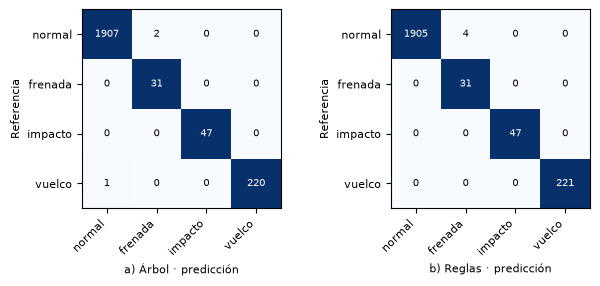

In [7]:
fig,axs=plt.subplots(1,2,figsize=(6.3,2.9))
for ax,pred,etiqueta in zip(axs,[test_w.tree_pred,test_w.rule_pred],['a) Árbol','b) Reglas']):
    m=confusion_matrix(y_test,pred,labels=CLASSES); proporcion=m / m.sum(axis=1,keepdims=True); ax.imshow(proporcion,cmap='Blues',vmin=0,vmax=1)
    for (i,j),v in np.ndenumerate(m): ax.text(j,i,str(v),ha='center',va='center',color='white' if proporcion[i,j]>.55 else 'black',fontsize=7)
    ax.set_xticks(range(4),CLASSES,rotation=45,ha='right'); ax.set_yticks(range(4),CLASSES); ax.set_xlabel(etiqueta+' · predicción'); ax.set_ylabel('Referencia')
    print(etiqueta, m.tolist())
fig.tight_layout(); guardar_fig(18,'matrices_sinteticas')

*Nota.* Filas: referencia; columnas: predicción. El color representa la proporción dentro de cada fila y las cifras son números de ventanas. Fuente: ventanas sintéticas reservadas. Elaboración propia.

**Tabla 22**

*Métricas sintéticas por clase*

In [8]:
filas=[]
for nombre,pred in [('Árbol',test_w.tree_pred),('Reglas',test_w.rule_pred)]:
 p,r,f,s=precision_recall_fscore_support(y_test,pred,labels=CLASSES,zero_division=0)
 for cl,a,b,c_,d in zip(CLASSES,p,r,f,s): filas.append([nombre,cl,a,b,c_,d])
tabla(pd.DataFrame(filas,columns=['Método','Clase','Precisión','Sensibilidad','F1','Ventanas']),22,'metricas_sinteticas')
print('Importancia:',dict(zip(FEATURES,model.feature_importances_.round(4))))
print('Profundidad:',model.get_depth(),'hojas:',model.get_n_leaves())

,Método,Clase,Precisión,Sensibilidad,F1,Ventanas
0,Árbol,normal,"1,000","0,999","0,999",1909
1,Árbol,frenada,"0,939","1,000","0,969",31
2,Árbol,impacto,"1,000","1,000","1,000",47
3,Árbol,vuelco,"1,000","0,996","0,998",221
4,Reglas,normal,"1,000","0,998","0,999",1909
5,Reglas,frenada,"0,886","1,000","0,939",31
6,Reglas,impacto,"1,000","1,000","1,000",47
7,Reglas,vuelco,"1,000","1,000","1,000",221


Importancia: {'acc_dyn_peak': np.float64(0.3334), 'acc_norm_delta_peak': np.float64(0.0), 'longitudinal_min_smooth': np.float64(0.3331), 'tilt_peak_deg': np.float64(0.0), 'tilt_time_s': np.float64(0.3334)}
Profundidad: 4 hojas: 7


*Nota.* La precisión, sensibilidad y F1 se calculan por clase. Fuente: ventanas reservadas. Elaboración propia.

Solo tres variables reparten la importancia; los cortes aprendidos coinciden aproximadamente con los umbrales usados para generar las etiquetas.

## 5. Aplicación a las 18 pruebas físicas

In [9]:
fisicas=make_windows(muestras,labeled=False); fisicas['clase']=model.predict(fisicas[FEATURES])
orden=pruebas.sort_values(['escenario','rep']).set_index('run_id')
recuento=pd.crosstab(fisicas.run_id,fisicas.clase).reindex(index=orden.index,columns=CLASSES,fill_value=0)


**Figura 19**

*Ventanas por clase y alarma en las pruebas físicas*

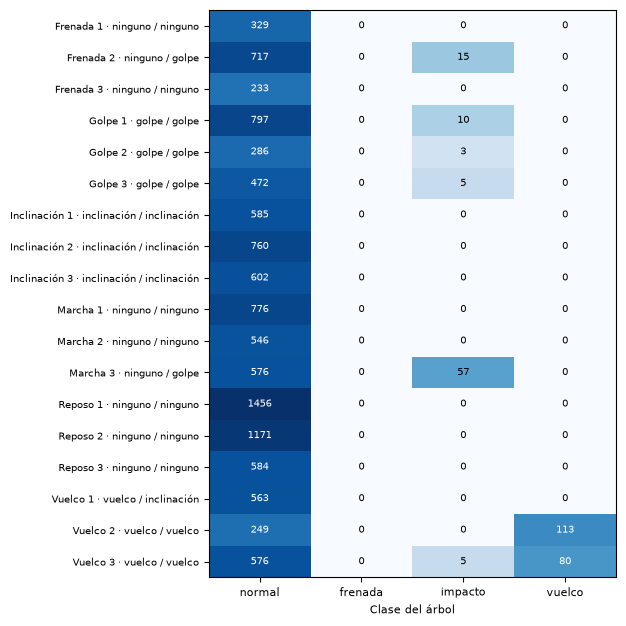

In [10]:
fig,ax=plt.subplots(figsize=(6.3,6.3)); mat=recuento.to_numpy(); ax.imshow(np.log1p(mat),cmap='Blues',aspect='auto')
for (i,j),v in np.ndenumerate(mat): ax.text(j,i,str(v),ha='center',va='center',fontsize=7,color='white' if np.log1p(v)>.6*np.log1p(mat.max()) else 'black')
ax.set_yticks(range(len(orden)),[f'{r.escenario} {r.rep} · {r.esperado} / {r.firmware}' for r in orden.itertuples()],fontsize=7); ax.set_xticks(range(4),CLASSES); ax.set_xlabel('Clase del árbol'); fig.tight_layout(); guardar_fig(19,'ventanas_fisicas')

*Nota.* Cada fila indica escenario y repetición, alarma esperada / firmware; los números son ventanas solapadas. Fuente: pruebas físicas. Elaboración propia.

**Tabla 23**

*Árbol y firmware en las pruebas físicas*

In [11]:
res=orden.join(recuento); cols=['frenada','impacto','vuelco']
res['dominante']=res[cols].idxmax(axis=1).where(res[cols].sum(axis=1)>0,'ninguna')
res['coincide']=res['dominante'].replace({'impacto':'golpe','ninguna':'ninguno'}).eq(res.esperado)
res['coincide'] = np.where(res.escenario.eq('Inclinación'), 'no aplica', np.where(res.coincide, 'sí', 'no'))
res['esperado'] = res.esperado.str.capitalize(); res['firmware'] = res.firmware.str.capitalize()
out=res.reset_index()[['escenario','rep','run_id','esperado','firmware','impacto','frenada','vuelco','dominante','coincide']]
out.columns=['Escenario','Repetición','Sesión','Esperado','Firmware','Impacto','Frenada','Vuelco','Dominante no normal','¿Coincide?']; tabla(out,23,'pruebas_fisicas'); print(out.to_string(index=False))

,Escenario,Repetición,Sesión,Esperado,Firmware,Impacto,Frenada,Vuelco,Dominante no normal,¿Coincide?
0,Frenada,1,RC-077000-CE13749F,Ninguno,Ninguno,0,0,0,ninguna,sí
1,Frenada,2,RC-077000-E624451E,Ninguno,Golpe,15,0,0,impacto,no
2,Frenada,3,RC-077000-64B894E7,Ninguno,Ninguno,0,0,0,ninguna,sí
3,Golpe,1,RC-077000-7B152E09,Golpe,Golpe,10,0,0,impacto,sí
4,Golpe,2,RC-077000-2BD0F270,Golpe,Golpe,3,0,0,impacto,sí
5,Golpe,3,RC-077000-CB1E9E4F,Golpe,Golpe,5,0,0,impacto,sí
6,Inclinación,1,RC-077000-B4A676B2,Inclinación,Inclinación,0,0,0,ninguna,no aplica
7,Inclinación,2,RC-077000-17EE06C6,Inclinación,Inclinación,0,0,0,ninguna,no aplica
8,Inclinación,3,RC-077000-7CC16D5A,Inclinación,Inclinación,0,0,0,ninguna,no aplica
9,Marcha,1,RC-077000-3458072A,Ninguno,Ninguno,0,0,0,ninguna,sí


  Escenario  Repetición             Sesión    Esperado    Firmware  Impacto  Frenada  Vuelco Dominante no normal ¿Coincide?
    Frenada           1 RC-077000-CE13749F     Ninguno     Ninguno        0        0       0             ninguna         sí
    Frenada           2 RC-077000-E624451E     Ninguno       Golpe       15        0       0             impacto         no
    Frenada           3 RC-077000-64B894E7     Ninguno     Ninguno        0        0       0             ninguna         sí
      Golpe           1 RC-077000-7B152E09       Golpe       Golpe       10        0       0             impacto         sí
      Golpe           2 RC-077000-2BD0F270       Golpe       Golpe        3        0       0             impacto         sí
      Golpe           3 RC-077000-CB1E9E4F       Golpe       Golpe        5        0       0             impacto         sí
Inclinación           1 RC-077000-B4A676B2 Inclinación Inclinación        0        0       0             ninguna  no aplica
Inclinac

*Nota.* La coincidencia compara la clase no normal dominante con la alarma esperada; en las tres pruebas de inclinación se indica «no aplica», porque el árbol no tiene esa clase. Fuente: Excel y registros físicos. Elaboración propia.

El árbol no reconoce ninguna frenada real; repite las falsas alarmas de golpe de Marcha 3 y Frenada 2. No ve el vuelco de costado de Vuelco 1, igual que el firmware. Estas diferencias ilustran la limitación del entrenamiento sintético.

## 6. Seguimiento de una decisión

Se selecciona la ventana cuyo centro está más cerca de la primera detección del firmware en Frenada 2.

In [12]:
ESCENARIO='Frenada'; REPETICION=2; SEGUNDO=None
coincide = pruebas.loc[pruebas.escenario.str.casefold().eq(ESCENARIO.casefold()) & pruebas.rep.eq(REPETICION)]
if len(coincide) != 1:
    raise ValueError("Elige un escenario y una repetición de la figura 3.")
sid = coincide.iloc[0].run_id
w = fisicas.loc[fisicas.run_id.eq(sid)].sort_values("t_center_s").reset_index(drop=True)
g = muestras.loc[muestras.run_id.eq(sid)].sort_values("t_ms")
ev = eventos.loc[eventos.run_id.eq(sid)].sort_values("t_deteccion_ms")
if SEGUNDO is None:
    objetivo = ev.iloc[0].t_deteccion_ms/1000 if len(ev) else w.t_center_s.median()
else:
    objetivo = float(SEGUNDO)
    if not w.t_start_s.min() <= objetivo <= w.t_end_s.max():
        raise ValueError(f"Elige un instante entre {w.t_start_s.min():.2f} y {w.t_end_s.max():.2f} s.")
fila = w.iloc[[(w.t_center_s-objetivo).abs().idxmin()]]
r = fila.iloc[0]
print(f"{ESCENARIO} {REPETICION} · {sid} · ventana {r.t_start_s:.2f}–{r.t_end_s:.2f} s · árbol: {r.clase}")


Frenada 2 · RC-077000-E624451E · ventana 7.82–8.32 s · árbol: normal


**Figura 20**

*Señal y clases del árbol en Frenada 2*

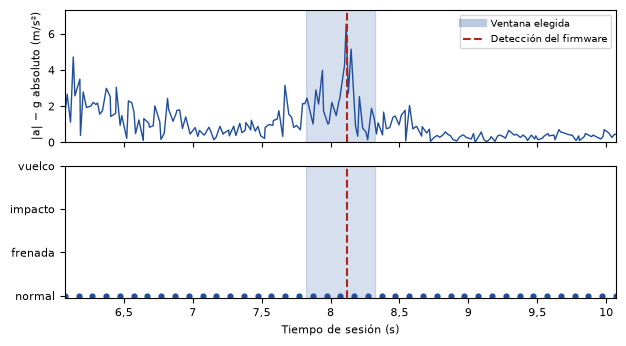

In [13]:
t=g.t_ms.to_numpy()/1000; acc=np.sqrt((g[['ax','ay','az']].to_numpy()**2).sum(axis=1)); lim=(max(t.min(),r.t_center_s-2),min(t.max(),r.t_center_s+2))
fig,(ax,ax2)=plt.subplots(2,1,figsize=(6.3,3.5),sharex=True)
ax.plot(t,np.abs(acc-G),color='#1f4e9c',lw=1); local=(t>=lim[0]) & (t<=lim[1]); maximo=np.abs(acc[local]-G).max(); ax.set_ylim(0,max(1,maximo*1.12)); ax.set_ylabel('|a| − g absoluto (m/s²)')
for eje in [ax,ax2]:
 eje.axvspan(r.t_start_s,r.t_end_s,color='#1f4e9c',alpha=.18)
 eje.axvline(objetivo,color='#b42318',ls='--')
for i,cl in enumerate(CLASSES):
 tmp=w[w.clase.eq(cl)&w.t_center_s.between(*lim)]; ax2.scatter(tmp.t_center_s,np.full(len(tmp),i),s=12,marker=['o','s','^','x'][i],color='#1f4e9c')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],color='#1f4e9c',lw=6,alpha=.3,label='Ventana elegida'),Line2D([0],[0],color='#b42318',ls='--',label='Detección del firmware')],fontsize=7,loc='upper right')
ax2.set(xlim=lim,yticks=range(4),yticklabels=CLASSES,xlabel='Tiempo de sesión (s)'); ax2.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt); fig.tight_layout(); guardar_fig(20,'senal_frenada_2')

*Nota.* La banda marca la ventana elegida y la línea discontinua la detección del firmware. Fuente: mediciones y eventos físicos. Elaboración propia.

In [14]:
arbol=model.tree_; ruta=list(model.decision_path(fila[FEATURES]).indices); hoja=int(model.apply(fila[FEATURES])[0]); pos={}; hojas=[]
def posicion(nivel,prof=0):
 izq,der=arbol.children_left[nivel],arbol.children_right[nivel]
 if izq==der: x=len(hojas); hojas.append(nivel)
 else: x=(posicion(izq,prof+1)+posicion(der,prof+1))/2
 pos[nivel]=(x,-prof); return x
posicion(0)

3.9375

**Figura 21**

*Recorrido de la ventana por el árbol*

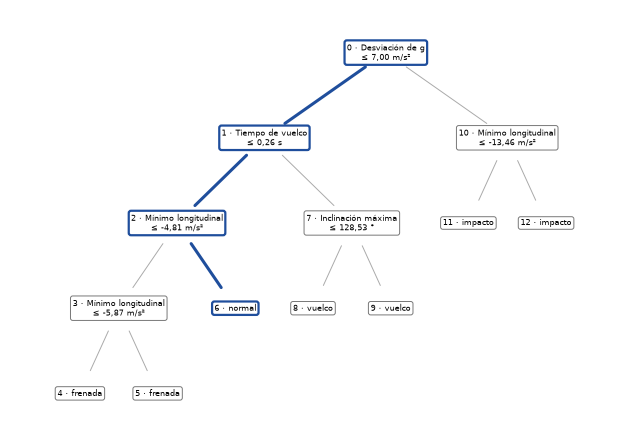

In [15]:
nombres_arbol = {'acc_dyn_peak': ('Desviación de g','m/s²'), 'acc_norm_delta_peak': ('Cambio de norma','m/s²'), 'longitudinal_min_smooth': ('Mínimo longitudinal','m/s²'), 'tilt_peak_deg': ('Inclinación máxima','°'), 'tilt_time_s': ('Tiempo de vuelco','s')}
fig,ax=plt.subplots(figsize=(6.3,4.5))
for nodo,(x,y) in pos.items():
 for hijo in [arbol.children_left[nodo],arbol.children_right[nodo]]:
  if hijo>=0: ax.annotate('',xy=pos[hijo],xytext=(x,y),arrowprops=dict(arrowstyle='-',color='#1f4e9c' if nodo in ruta and hijo in ruta else '#aaaaaa',lw=2.2 if nodo in ruta and hijo in ruta else .7,shrinkA=18,shrinkB=18))
for nodo,(x,y) in pos.items():
 if arbol.children_left[nodo]<0:
  etiqueta=f"{nodo} · {model.classes_[arbol.value[nodo][0].argmax()]}"
 else:
  nombre,unidad=nombres_arbol[FEATURES[arbol.feature[nodo]]]; umbral=f'{arbol.threshold[nodo]:.2f}'.replace('.',','); etiqueta=f'{nodo} · {nombre}\n≤ {umbral} {unidad}'
 ax.text(x,y,etiqueta,ha='center',va='center',fontsize=5.5,bbox=dict(boxstyle='round,pad=.3',fc='white',ec='#1f4e9c' if nodo in ruta else '#777777',lw=1.6 if nodo in ruta else .7))
ax.set_xlim(-.9,len(hojas)-.1); ax.set_ylim(-arbol.max_depth-.5,.5); ax.axis('off'); fig.tight_layout(); guardar_fig(21,'recorrido_arbol')

*Nota.* El trazo azul y más grueso destaca el recorrido; los números identifican nodos. Fuente: árbol entrenado y ventana seleccionada. Elaboración propia.

**Tabla 24**

*Recorrido de la ventana seleccionada*

In [16]:
pasos=[]
for nodo,sig in zip(ruta,ruta[1:]):
 variable=FEATURES[arbol.feature[nodo]]; nombre,unidad=nombres_arbol[variable]
 pasos.append([nodo,variable,nombre,unidad,round(float(r[variable]),2),round(float(arbol.threshold[nodo]),2),'izquierda (≤)' if sig==arbol.children_left[nodo] else 'derecha (>)'])
df_pasos=pd.DataFrame(pasos,columns=['Nodo','Variable','Nombre en español','Unidad','Valor de ventana','Umbral','Rama'])
df_pasos.to_csv(datos/'tabla24_recorrido.csv',index=False,float_format='%.2f')
display(df_pasos.style.format(precision=2,decimal=','))

,Nodo,Variable,Nombre en español,Unidad,Valor de ventana,Umbral,Rama
0,0,acc_dyn_peak,Desviación de g,m/s²,"6,54","7,00",izquierda (≤)
1,1,tilt_time_s,Tiempo de vuelco,s,"0,00","0,26",izquierda (≤)
2,2,longitudinal_min_smooth,Mínimo longitudinal,m/s²,"-1,89","-4,81",derecha (>)


*Nota.* La rama izquierda satisface el umbral. Fuente: árbol entrenado. Elaboración propia.

In [17]:
#@title Funciones del informe de la versión 0.2
API_EVENT_TYPE = {"impacto":"golpe","vuelco":"vuelco","inclinacion":"inclinacion"}
def merge_events(pred_windows, pred_col="prediction", gap_s=0.25):
    events = []
    p = pred_windows.sort_values("t_center_s")
    for _, r in p[p[pred_col] != "normal"].iterrows():
        cls = r[pred_col]
        if events and events[-1]["type"] == cls and r.t_start_s <= events[-1]["end_s"] + gap_s:
            events[-1]["end_s"] = max(events[-1]["end_s"], float(r.t_end_s))
            events[-1]["_probs"].append(float(r.max_probability))
        else:
            events.append({"type": cls, "start_s": float(r.t_start_s), "end_s": float(r.t_end_s),
                           "_probs": [float(r.max_probability)]})
    return events

def make_verdict(run_df, fitted_model=None):
    fitted_model = fitted_model or model
    g, _ = validate_data(run_df)
    rid = str(g.run_id.iloc[0]); origin = str(g.origin.iloc[0])
    numeric = ["t_ms", "ax", "ay", "az", "roll_deg", "pitch_deg"]
    total = len(g)
    miss_count = int(g[numeric].isna().sum().sum())
    g = g.dropna(subset=numeric).reset_index(drop=True)
    t = g.t_ms.to_numpy(float)/1000
    period = sample_period(g.t_ms)
    gaps = np.diff(t)
    gap_flag = bool(len(gaps) and np.any(gaps > max(0.1, 3*period)))
    backwards = bool(len(gaps) and np.any(gaps < 0))
    w = make_windows(g, labeled=False) if not backwards else pd.DataFrame()
    base = {"run_id": rid, "origin": origin, "model_version": MODEL_VERSION}
    if len(w) == 0:
        return {**base, "status": "incierto", "events": [], "final_posture": "no estimable",
                "text": "Datos insuficientes para determinar qué ocurrió."}
    probs = fitted_model.predict_proba(w[FEATURES])
    w["prediction"] = fitted_model.predict(w[FEATURES])
    w["max_probability"] = probs.max(axis=1)
    # Filtro declarado: solo es "frenada brusca" si la desaceleración suavizada supera el umbral.
    w.loc[(w.prediction == "frenada") & (w.longitudinal_min_smooth > BRAKE_THRESHOLD), "prediction"] = "normal"
    events = merge_events(w)

    an = np.sqrt(g.ax**2 + g.ay**2 + g.az**2).to_numpy(float)
    tilt = np.maximum(g.roll_deg.abs(), g.pitch_deg.abs()).to_numpy(float)
    k = max(1, int(round(SMOOTH_S/period)))
    ax_s = pd.Series(g.ax.to_numpy(float)).rolling(k, center=True, min_periods=1).mean().to_numpy()

    # Momento de cada evento = instante medido dentro de su intervalo, no el borde de la ventana.
    for e in events:
        m = (t >= e["start_s"] - 1e-9) & (t <= e["end_s"] + 1e-9)
        idx = np.flatnonzero(m)
        if e["type"] == "impacto":
            i = idx[np.argmax(np.abs(an[m] - G))]
        elif e["type"] == "vuelco":
            over = idx[tilt[m] > ROLLOVER_DEG]; i = over[0] if len(over) else idx[np.argmax(tilt[m])]
        else:
            i = idx[np.argmin(ax_s[m])]
        e["time_s"] = round(float(t[i]), 2)
        e["start_s"] = round(e["start_s"], 2); e["end_s"] = round(e["end_s"], 2)
        e["peak_acceleration_m_s2"] = round(float(an[m].max()), 2)
        e["min_longitudinal_m_s2"] = round(float(ax_s[m].min()), 2)
        e["max_tilt_deg"] = round(float(tilt[m].max()), 2)
        e["confidence"] = round(float(np.mean(e.pop("_probs"))), 2)
        e["source"] = "arbol"

    # Inclinación sostenida sin vuelco: regla explícita (misma idea que la web), no sale del árbol.
    if not any(e["type"] == "vuelco" for e in events):
        run_len, start_i = 0, None
        for i, v in enumerate((tilt >= TILT_WARN_DEG) & (tilt <= ROLLOVER_DEG)):
            if v:
                start_i = i if run_len == 0 else start_i; run_len += 1
                if run_len*period >= TILT_WARN_S:
                    j = i
                    while j+1 < len(tilt) and tilt[j+1] >= TILT_WARN_DEG: j += 1
                    seg = slice(start_i, j+1)
                    events.append({"type": "inclinacion", "start_s": round(float(t[start_i]), 2), "end_s": round(float(t[j]), 2),
                                   "time_s": round(float(t[start_i]), 2), "peak_acceleration_m_s2": round(float(an[seg].max()), 2),
                                   "min_longitudinal_m_s2": round(float(ax_s[seg].min()), 2),
                                   "max_tilt_deg": round(float(tilt[seg].max()), 2), "confidence": None, "source": "regla"})
                    break
            else:
                run_len = 0
    events.sort(key=lambda e: e["time_s"])
    for e in events:
        e["api_tipo"] = API_EVENT_TYPE.get(e["type"])      # None para 'frenada': la API no la registra como evento

    low_conf = any(e["confidence"] is not None and e["confidence"] < 0.45 for e in events)
    uncertain = (miss_count > 0.05*total*6) or gap_flag or low_conf
    final_roll = float(g.roll_deg.iloc[-1]); final_pitch = float(g.pitch_deg.iloc[-1])
    final_tilt = max(abs(final_roll), abs(final_pitch))
    posture = ("volcado al final" if final_tilt > ROLLOVER_DEG else
               "inclinado al final" if final_tilt > 25 else "aproximadamente nivelado")

    status = "incierto" if uncertain else ("eventos_detectados" if events else "normal")
    if uncertain:
        sentence = "Datos insuficientes para determinar qué ocurrió con confianza; se requiere revisar la señal y/o el video."
    elif not events:
        sentence = "Durante esta corrida no se detectaron señales de frenada brusca, impacto, inclinación sostenida ni vuelco."
    else:
        parts = []
        for e in events:
            phrase = f"{e['type'].replace('inclinacion','inclinación sostenida')} cerca del segundo {e['time_s']:.2f}"
            if e["type"] == "impacto": phrase += f", con pico de aceleración total de {e['peak_acceleration_m_s2']:.2f} m/s²"
            if e["type"] == "frenada": phrase += f", con desaceleración de {abs(e['min_longitudinal_m_s2']):.2f} m/s²"
            if e["type"] in ("vuelco", "inclinacion"): phrase += f", con inclinación máxima de {e['max_tilt_deg']:.1f}°"
            parts.append(phrase)
        sentence = "Se detectó " + "; seguido de ".join(parts) + "."
    if gap_flag:
        sentence += " Se observó un corte o salto temporal de señal; revisar el intervalo."
    tilt_peak = float(tilt.max())
    if 35 <= tilt_peak <= ROLLOVER_DEG and not any(e["type"] in ("inclinacion", "vuelco") for e in events):
        sentence += f" La inclinación máxima fue {tilt_peak:.1f}°, sin llegar a inclinación sostenida ni vuelco."
    sentence += f" El carro terminó {posture}."
    return {**base, "status": status, "events": events,
            "peak_acceleration_m_s2": round(float(an.max()), 2),
            "min_longitudinal_m_s2": round(float(ax_s.min()), 2),
            "max_tilt_deg": round(tilt_peak, 2),
            "final_roll_deg": round(final_roll, 2), "final_pitch_deg": round(final_pitch, 2),
            "final_posture": posture, "duration_s": round(float(t[-1]-t[0]), 2),
            "sample_rate_hz": round(1/period, 1),
            "missing_numeric_values": miss_count, "signal_gap_detected": gap_flag,
            "uncertainty_note": "confidence es la proporción de la hoja del árbol, no una probabilidad calibrada.",
            "text": sentence}
informe = make_verdict(g,model)
print(informe["text"])

Se detectó impacto cerca del segundo 12.85, con pico de aceleración total de 16.97 m/s²; seguido de impacto cerca del segundo 21.00, con pico de aceleración total de 21.54 m/s²; seguido de impacto cerca del segundo 33.04, con pico de aceleración total de 35.94 m/s². El carro terminó aproximadamente nivelado.


## 7. Calibración del ángulo

Se usan 13 medidas reales, con una app de nivel del celular como referencia (incertidumbre aproximada ±0,5–1°). La figura de calibración ya aparece como figura 12 del informe; aquí no se exporta otra.

**Tabla 25**

*Ajuste del ángulo real frente al MPU*

In [18]:
import csv
with open((raiz/'datos/calibracion_angulo.csv' if (raiz/'datos/calibracion_angulo.csv').exists() else datos/'calibracion_angulo.csv'),encoding='utf-8',newline='') as f:
 filas=list(csv.reader(f)); cal=pd.DataFrame([row[:4] for row in filas[1:] if row and not row[3].startswith('EJEMPLO')],columns=filas[0])
x=cal.angulo_mpu_grados.astype(float).to_numpy(); y=cal.angulo_real_grados.astype(float).to_numpy(); resultados=[]
for grado in [1,2]:
 coef=np.polyfit(x,y,grado); pred=np.polyval(coef,x); resid=y-pred; r2=1-(resid@resid)/((y-y.mean())@(y-y.mean())); ajustado=1-(1-r2)*(len(y)-1)/(len(y)-grado-1)
 resultados.append([grado,r2,ajustado,np.mean(np.abs(resid)),np.sqrt(np.mean(resid**2))])
 if grado==1: print('Pendiente e intercepto:',coef); assert np.allclose(coef,[1.0085,-.7064],atol=.0001)
tabla(pd.DataFrame(resultados,columns=['Grado','R²','R² ajustado','Error medio absoluto (°)','RMSE (°)']),25,'ajuste_angulo')

Pendiente e intercepto: [ 1.00849181 -0.70639287]


,Grado,R²,R² ajustado,Error medio absoluto (°),RMSE (°)
0,1,"0,998","0,997","1,259","1,604"
1,2,"0,998","0,998","1,217","1,474"


*Nota.* El error medio es absoluto. Fuente: calibracion_angulo.csv; referencia mediante app de nivel. Elaboración propia.

## 8. Limitaciones y trabajo futuro

Se necesitan maniobras físicas etiquetadas con inicio y fin, sesiones independientes reservadas para evaluación y más frenadas reales. Debe estudiarse el umbral de vuelco de costado: el carro quedó aproximadamente a 81°. El Hall carecía de imán durante estas pruebas, por lo que no se dispone de velocidad de rueda fiable.